# TOVIS (*TO*nal *VIS*ualization toolbox): _Structure Analysis_
Johannes Zeitler and Meinard Müller, 2026

In [1]:
import matplotlib.pyplot as plt

import os

from tovis.feature import compute_chromagram_from_file
from tovis.utils import read_csv, get_exp_and_repr_limits, shorten_annotation, measures_to_time, key_to_relative_major
from tovis.structure import get_ssm_ti, crop_ssm_ti, get_optimizing_path, get_ssm_index_ti_at_path
from tovis.visualization import plot_transposition_index_matrix, overlay_structure_annotations, overlay_measure_annotations, plot_transposition_index, plot_features_and_ssm, plot_features_and_alignment, plot_scale_likelihood, overlay_lines, overlay_correspondence_annotations
from tovis.scale import scale_analysis_templates

Specify dataset path, piece, version, and load annotations

In [2]:
BPSD_DIR = os.path.join("data", "BPSD")

piece = "Beethoven_Op014No2-01"
version = "WK64"

ann_audio_measure = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_measure", piece + "_" + version + ".csv"))
ann_audio_structureCoarse = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_structureCoarse", piece + "_" + version + ".csv"))
ann_audio_structureFine = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_structureFine", piece + "_" + version + ".csv"))
ann_audio_localkey = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_localkey", piece + "_" + version + ".csv"))

global_key = key_to_relative_major(ann_audio_localkey.loc[0].localkey)

Compute a chromagram from an audio file

In [3]:
chromagram_STFT, sr_chromagram_STFT = compute_chromagram_from_file(os.path.join(BPSD_DIR, "1_Audio", piece + "_" + version + ".mp3"), 
                                                         backend="STFT",
                                                         smoothing_length_seconds=4,
                                                         output_feature_rate=2)

Compute and plot a transposition-invariant self-similarity matrix

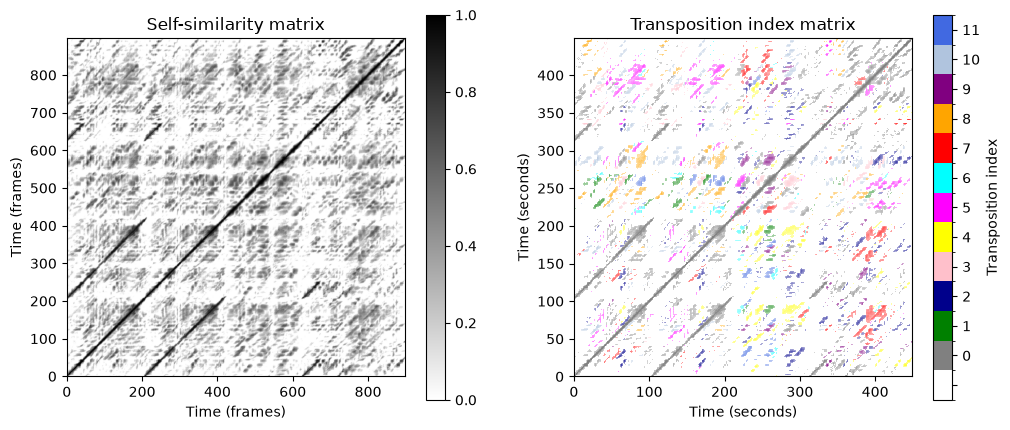

In [4]:
ssm_ti, index_ti = get_ssm_ti(feature_sequence=chromagram_STFT, feature_rate=sr_chromagram_STFT, smoothing_length_seconds=6, tempo_deviation=0.3, 
                              direction="both", 
                              min_similarity_for_index=0.3, thresh=0.4, threshold_strategy="relative", norm="2", 
                                scale=True, penalty=-2.)
fig, ax = plt.subplots(1, 2, figsize=(12,5))

im0 = ax[0].imshow(ssm_ti, aspect="equal", cmap="gray_r", origin="lower", clim=[0.0,1])
ax[0].set_title("Self-similarity matrix")
ax[0].set_xlabel("Time (frames)")
ax[0].set_ylabel("Time (frames)")
plt.colorbar(im0, ax=ax[0])

plot_transposition_index_matrix(index_ti, ssm_ti=ssm_ti, ax=ax[1], feature_rate=sr_chromagram_STFT)

plt.show()

Zoom into the Exposition/Reprise area

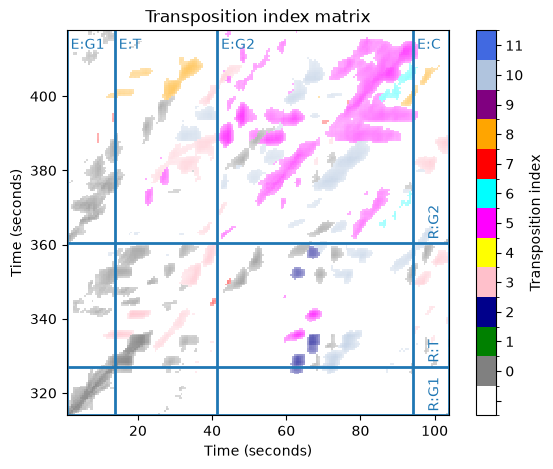

In [6]:
limits_exp, limits_repr = get_exp_and_repr_limits(ann_audio_structureCoarse)

fig, ax = plt.subplots(1,1, figsize=(7,5))

plot_transposition_index_matrix(index_ti, ssm_ti=ssm_ti, ax=ax, feature_rate=sr_chromagram_STFT, xlim=limits_exp, ylim=limits_repr) 
overlay_structure_annotations(ann_audio_structureFine, ax=ax, direction="vertical", shorten_annotation=True)
overlay_structure_annotations(ann_audio_structureFine, ax=ax, direction="horizontal", shorten_annotation=True)

plt.show()

Crop the SSM to the exposition/recap area and compute an optimizing path through it. We choose "partial_matching" as a path-finding method, since it supports discontinuities in the alignment path.

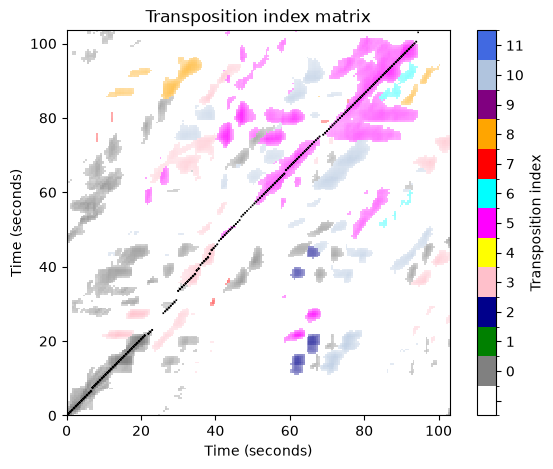

In [7]:
ssm_ti_crop, index_ti_crop = crop_ssm_ti(ssm_ti, index_ti, feature_rate=sr_chromagram_STFT,
                                         x_range=limits_exp,y_range=limits_repr)

opt_path = get_optimizing_path(ssm_ti_crop, method="partial_matching")

ssm_path, index_path = get_ssm_index_ti_at_path(ssm_ti_crop, index_ti_crop,
                                                path=opt_path,
                                                normalize_ssm=True)
fig, ax = plt.subplots(1,1, figsize=(7,5))

plot_transposition_index_matrix(index_ti_crop, ssm_ti=ssm_ti_crop, ax=ax, feature_rate=sr_chromagram_STFT)
ax.scatter(opt_path[:,1]/sr_chromagram_STFT, opt_path[:,0]/sr_chromagram_STFT, marker="x", s=ssm_path, color="k")
plt.show()


Next, we overlay structure (parts) and correspondence annotations. The part annotations are given as a pandas DataFrame, where every row indicates the start, end, name, and harmony of a structural segment. The correspondence annotations are also given as pandas DataFrames, but every row lists the names of all parts that correspond to one another.

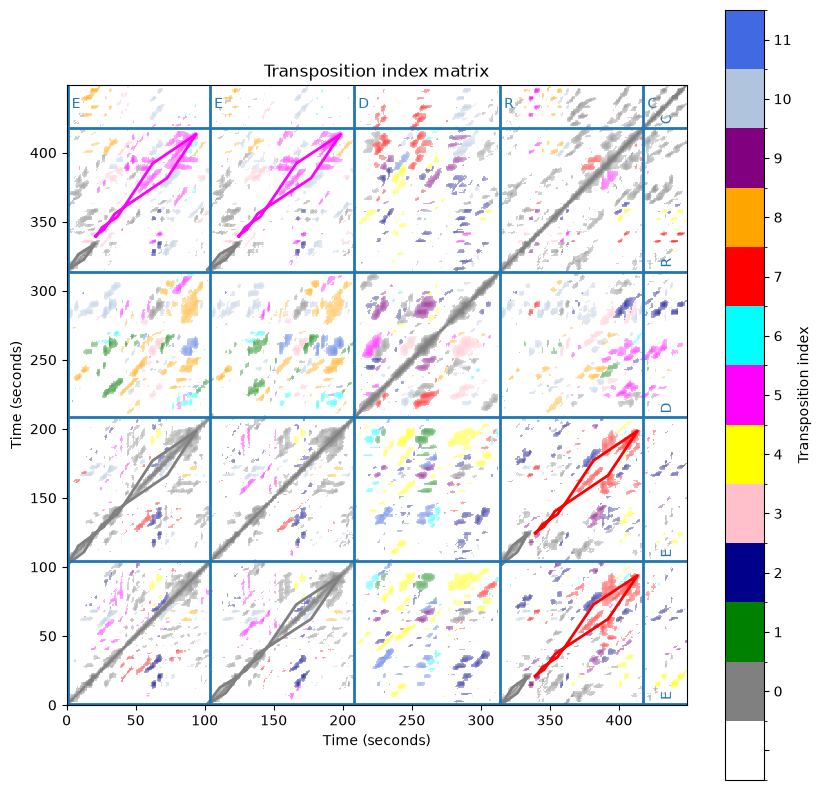

In [9]:
ann_score_parts = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_score_correspondences", piece+"_parts.csv"))
ann_score_correspondences = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_score_correspondences", piece+"_correspondences.csv"))

ann_audio_parts = measures_to_time(ann_score_parts,
                                   sync_annotation=ann_audio_measure,
                                   columns=["start_meas", "end_meas"],
                                   output_columns=["start", "end"])

fig, ax = plt.subplots(1,1, figsize=(10,10))

plot_transposition_index_matrix(index_ti, ssm_ti=ssm_ti, ax=ax, feature_rate=sr_chromagram_STFT)

overlay_correspondence_annotations(ann_parts=ann_audio_parts,
                                   ann_correspondences=ann_score_correspondences,
                                   ax=ax)

overlay_structure_annotations(shorten_annotation(ann_audio_structureCoarse), ax=ax, direction="vertical")
overlay_structure_annotations(shorten_annotation(ann_audio_structureCoarse), ax=ax, direction="horizontal")
plt.show()

Plot features and the computed alignment

In [10]:
chromagram_IIR, sr_chromagram_IIR = compute_chromagram_from_file(os.path.join(BPSD_DIR, "1_Audio", piece + "_" + version + ".mp3"), 
                                                         backend="IIR",
                                                         smoothing_length_seconds=4,
                                                         output_feature_rate=1)


scale_likelihood = scale_analysis_templates(chromagram=chromagram_IIR,
                                            template_version="triads_enhanced",
                                            method="exp_product",
                                            apply_softmax_rescaling=True,
                                            softmax_eta=10)
scale_likelihood_exp = scale_likelihood[:,int(limits_exp[0]*sr_chromagram_IIR):int(limits_exp[1]*sr_chromagram_IIR)]
scale_likelihood_repr = scale_likelihood[:,int(limits_repr[0]*sr_chromagram_IIR):int(limits_repr[1]*sr_chromagram_IIR)]

/tmp/ipykernel_288907/3970270866.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


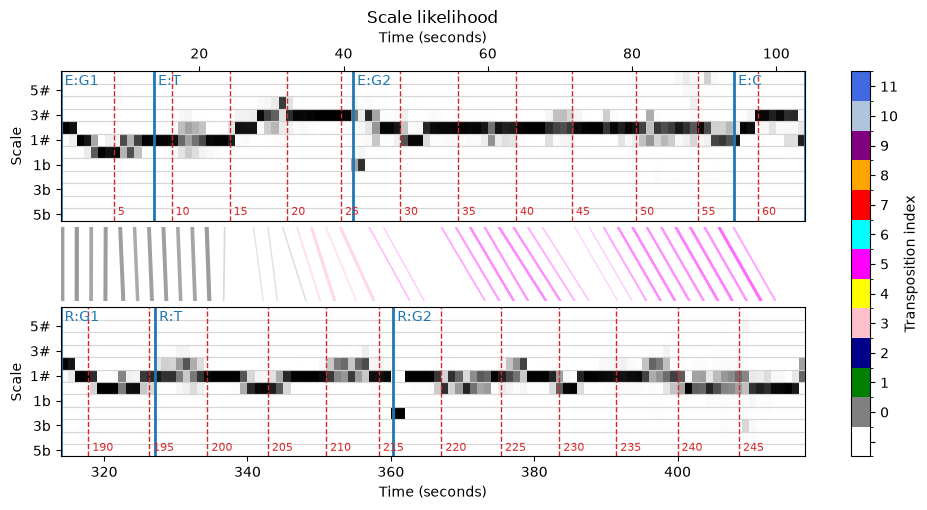

In [11]:
fig, ax, im, lines = plot_features_and_alignment(duration_x=limits_exp[1]-limits_exp[0],
                                                 duration_y=limits_repr[1]-limits_repr[0],
                                                    path=opt_path,
                                                    ssm_path=ssm_path,
                                                    index_ti_path=index_path,
                                                    feature_rate_path=sr_chromagram_STFT,
                                                    alignment_hop=4,
                                                    colorbar=True,
                                                    ssm_controls_alpha=True,
                                                    ssm_controls_linewidth=True,
                                                    figsize=(12,5))



plot_scale_likelihood(scale_likelihood, feature_rate=sr_chromagram_IIR,
                      sort_by_fifths=True,
                      ax=ax[0],
                      global_key=global_key, 
                      colorbar=False,
                      xlim=limits_exp,
                      ytick_label_hop=2)

plot_scale_likelihood(scale_likelihood, feature_rate=sr_chromagram_IIR,
                      sort_by_fifths=True,
                      ax=ax[2],
                      global_key=global_key, 
                      colorbar=False,
                      xlim=limits_repr,
                      ytick_label_hop=2)

ax[0].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)

overlay_lines(ax=ax[0], direction="horizontal")

overlay_lines(ax=ax[2], direction="horizontal")

overlay_measure_annotations(ann_audio_measure,measure_annotation_hop=5,ax=ax[0])
overlay_measure_annotations(ann_audio_measure,measure_annotation_hop=5,ax=ax[2])
overlay_structure_annotations(ann_audio_structureFine,ax=ax[0], shorten_annotation=True)
overlay_structure_annotations(ann_audio_structureFine,ax=ax[2], shorten_annotation=True)

ax[2].set_title("")
fig.tight_layout()
plt.show()

Plot the transposition index

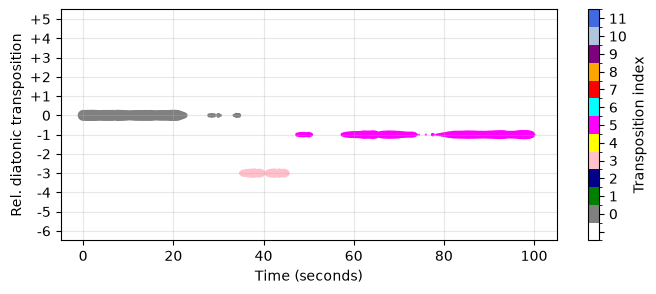

In [18]:
plot_transposition_index(index_ti_path=index_path,
                         path=opt_path,
                         feature_rate=sr_chromagram_STFT,
                         ssm_path=ssm_path,
                         sort_by_fifths=True)
plt.show()

Plot features, SSM, and annotations

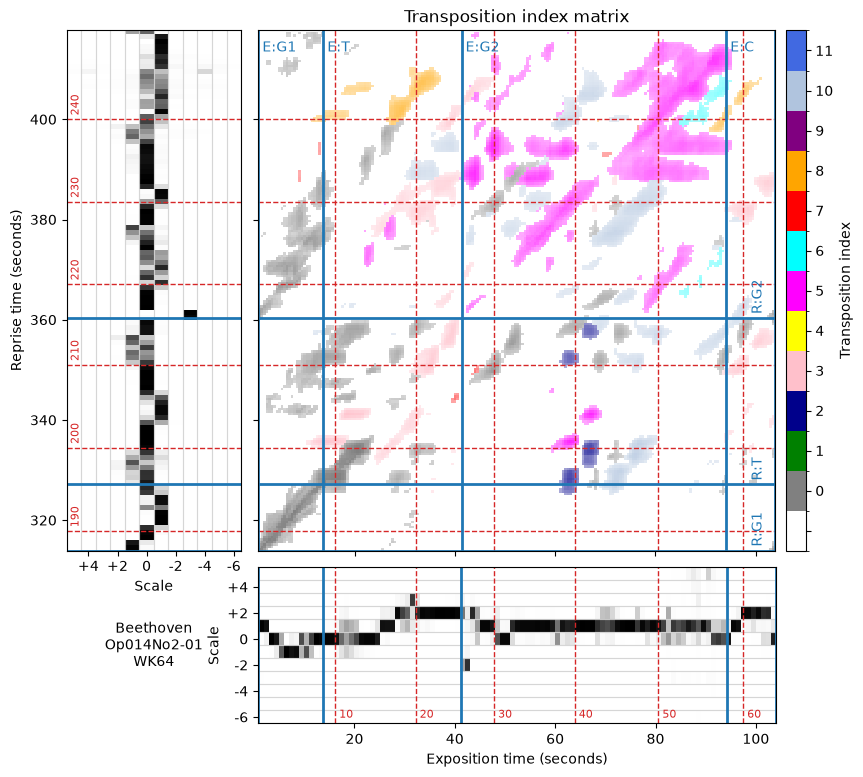

In [14]:
fig, ax, im = plot_features_and_ssm(index_ti=index_ti_crop,
                                    ssm_ti=ssm_ti_crop,
                                    ssm_offset_x=limits_exp[0],
                                    ssm_offset_y=limits_repr[0],
                                    feature_rate_ssm=sr_chromagram_STFT,
                                    corner_text="%s\n%s"%("\n".join(piece.split("_")), version))

plot_scale_likelihood(scale_likelihood, 
                      xlim=limits_exp, 
                      feature_rate=sr_chromagram_IIR, 
                      ax=ax[1], 
                      colorbar=False,
                      sort_by_fifths=True,
                      global_key=global_key,
                      scale_label_version="relative_diatonic",
                      ytick_label_hop=2,
                      title=None,
                      xlabel="Exposition time (seconds)")

plot_scale_likelihood(scale_likelihood, 
                      xlim=limits_repr, 
                      feature_rate=sr_chromagram_IIR, 
                      ax=ax[2], 
                      colorbar=False,
                      sort_by_fifths=True,
                      global_key=global_key,
                      scale_label_version="relative_diatonic",
                      ytick_label_hop=2,
                      direction="vertical",
                      title=None,
                      xlabel="Reprise time (seconds)")

overlay_measure_annotations(ann_audio_measure,measure_annotation_hop=10,
                            ax=ax[0],
                            labels=False)

overlay_measure_annotations(ann_audio_measure,measure_annotation_hop=10,
                            ax=ax[1],
                            labels=True)

overlay_measure_annotations(ann_audio_measure,measure_annotation_hop=10,
                            ax=ax[0],
                            labels=False,
                            direction="horizontal")

overlay_measure_annotations(ann_audio_measure,measure_annotation_hop=10,
                            ax=ax[2],
                            labels=True,
                            direction="horizontal")

overlay_structure_annotations(ann_audio_structureFine,
                              shorten_annotation=True,
                                ax=ax[0],
                                labels=True)

overlay_structure_annotations(ann_audio_structureFine,
                              shorten_annotation=True,
                                ax=ax[1],
                                labels=False)

overlay_structure_annotations(ann_audio_structureFine,
                              shorten_annotation=True,
                                ax=ax[0],
                                labels=True,
                                direction="horizontal")

overlay_structure_annotations(ann_audio_structureFine,
                              shorten_annotation=True,
                                ax=ax[2],
                                labels=False,
                                direction="horizontal")

overlay_lines(ax[1], direction="horizontal")
overlay_lines(ax[2], direction="vertical")

#fig.tight_layout()
plt.show()
